# 03 · Commuting: who already travels to Canary Wharf?

Census 2021 origin–destination flows (ODWP01EW) at MSOA level: residents of
each MSOA by the MSOA they work in. We count how many people living near the
south portal already commute to Canary Wharf, and how many in the wider area
gain access time from the tunnel.

**Caveat:** Census day was 21 March 2021, during lockdown. Many office
workers were furloughed or working from home, and ONS warns that the
workplace data should be used with care. Treat these counts as a floor.

Source: Office for National Statistics, Census 2021, licensed under the OGL v3.0.


In [1]:
import zipfile

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from shapely.geometry import Point

from common import BNG, CANARY_WHARF, DERIVED, FIGURES, RAW, WGS84, attach_access, ons_layer

msoa = ons_layer("Middle_layer_Super_Output_Areas_December_2021_Boundaries_EW_BGC_V3")
oa = ons_layer("OA_December_2021_EW_PWC_V4")

In [2]:
with zipfile.ZipFile(RAW / "odwp01ew.zip") as z, z.open("ODWP01EW_MSOA.csv") as f:
    od = pd.read_csv(f, usecols=[0, 2, 6], names=["home", "work", "count"], header=0)
od = od[od["work"].str.startswith("E", na=False)]
jobs = od.groupby("work")["count"].sum()

## Which MSOAs are "Canary Wharf"?

MSOAs within 700 m of One Canada Square, ranked by Census-day jobs. Keep the ones
that are clearly the office cluster.


In [3]:
cw_point = gpd.GeoSeries([Point(*CANARY_WHARF)], crs=WGS84).to_crs(BNG).buffer(700).to_crs(WGS84).iloc[0]
near = msoa[msoa.intersects(cw_point)][["MSOA21CD", "MSOA21NM"]].copy()
near["jobs_census_day"] = near["MSOA21CD"].map(jobs)
near.sort_values("jobs_census_day", ascending=False)

,MSOA21CD,MSOA21NM,jobs_census_day
61,E02006854,Tower Hamlets 033,24528
73,E02007113,Tower Hamlets 035,7070
60,E02006853,Tower Hamlets 032,5446
74,E02007114,Tower Hamlets 036,4453
52,E02000886,Tower Hamlets 023,4278
53,E02000887,Tower Hamlets 024,3900
49,E02000883,Tower Hamlets 020,3070


In [ ]:
CW_MIN_JOBS = (
    5_000  # Census-day jobs; separates the office cluster (core, Wood Wharf, South Quay) from residential neighbours
)
CW_MSOAS = near.loc[near.jobs_census_day >= CW_MIN_JOBS, "MSOA21CD"].tolist()
print("Canary Wharf workplace MSOAs:", near.set_index("MSOA21CD").loc[CW_MSOAS, "MSOA21NM"].tolist())

Canary Wharf workplace MSOAs: ['Tower Hamlets 032', 'Tower Hamlets 033', 'Tower Hamlets 035']


## Commuters to Canary Wharf by home MSOA


In [ ]:
workers = od[od["home"].isin(msoa.MSOA21CD)]
by_home = workers.groupby("home")["count"].sum().rename("employed")
to_cw = workers[workers["work"].isin(CW_MSOAS)].groupby("home")["count"].sum().rename("to_cw")
flows = msoa.set_index("MSOA21CD").join([by_home, to_cw]).fillna({"to_cw": 0})
flows["share_to_cw"] = flows["to_cw"] / flows["employed"]

# Mean tunnel time saving across each MSOA's output areas (population-weighted centroids)
oa_access = attach_access(oa)
oa_access["saving"] = oa_access["access_before"] - oa_access["access_after"]
oa_access["cycle_saving"] = oa_access["cycle_before"] - oa_access["cycle_after"]
oa_msoa = gpd.sjoin(oa_access.to_crs(WGS84), msoa[["MSOA21CD", "geometry"]], predicate="within")
flows = flows.join(oa_msoa.groupby("MSOA21CD")[["saving", "cycle_saving"]].mean())
flows = gpd.GeoDataFrame(flows, geometry="geometry", crs=WGS84)

gainers = flows[(flows.saving >= 1) & ~flows.index.isin(CW_MSOAS)]
print(f"MSOAs with ≥1 min average walk/PT saving: {len(gainers)}")
gainers[["MSOA21NM", "employed", "to_cw", "share_to_cw", "saving", "cycle_saving"]].sort_values(
    "saving", ascending=False
).round(2)

MSOAs with ≥1 min average walk/PT saving: 1


,MSOA21NM,employed,to_cw,share_to_cw,saving,cycle_saving
MSOA21CD,,,,,,
E02000814,Southwark 008,6520,71,0.01,1.94,21.98


In [ ]:
cyc = flows[(flows.cycle_saving >= 5) & ~flows.index.isin(CW_MSOAS)]
print(
    f"MSOAs with ≥5 min average cycling saving: {len(cyc)}, "
    f"{int(cyc.to_cw.sum()):,} Census-day Canary Wharf commuters, {int(cyc.employed.sum()):,} employed residents"
)

MSOAs with ≥5 min average cycling saving: 21, 645 Census-day Canary Wharf commuters, 107,581 employed residents


## Map


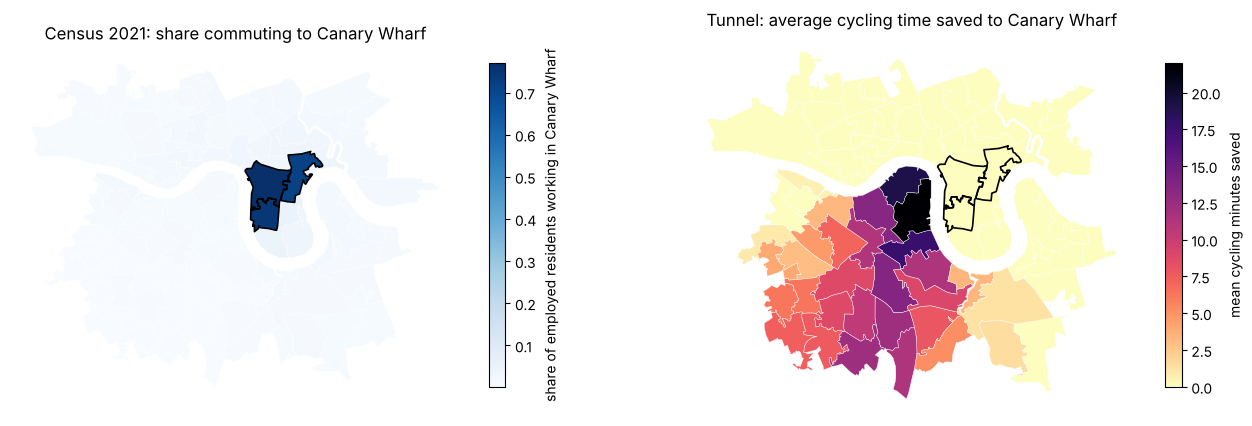

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
flows.plot(
    ax=axes[0],
    column="share_to_cw",
    cmap="Blues",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    legend_kwds={"label": "share of employed residents working in Canary Wharf", "shrink": 0.6},
)
axes[0].set_title("Census 2021: share commuting to Canary Wharf")
flows.plot(
    ax=axes[1],
    column="cycle_saving",
    cmap="magma_r",
    legend=True,
    edgecolor="white",
    linewidth=0.3,
    vmin=0,
    legend_kwds={"label": "mean cycling minutes saved", "shrink": 0.6},
)
axes[1].set_title("Tunnel: average cycling time saved to Canary Wharf")
for ax in axes:
    flows[flows.index.isin(CW_MSOAS)].boundary.plot(ax=ax, color="black", linewidth=1.2)
    ax.set_axis_off()
fig.savefig(FIGURES / "03_commuting.png", dpi=150, bbox_inches="tight")

In [8]:
flows.drop(columns="geometry").to_csv(DERIVED / "msoa_commuting.csv")